In [1]:
import torch
from torch import nn, optim, functional as F
from torchvision import datasets, transforms
from torch.nn import functional as F
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch_size = 256

trainset = datasets.MNIST("./dataset/", train = True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train = False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
	dataset,
	batch_size = batch_size,
	shuffle = True
)

tensor_to_img = transforms.ToPILImage()

## Convolutional VAE

### Train

In [ ]:
activation_func = "Conv_VAE_beta"

class Conv_VAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(
                1, 32, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
            ),  # 28 -> 14
            nn.ReLU(),

            nn.Conv2d(
                32, 64, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
            ), # 14 -> 7
            nn.ReLU(),

            nn.Flatten()
        )

        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 7 * 7),
            nn.Unflatten(1, (64, 7, 7)),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 7 -> 14
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 14 -> 28
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvae = self.fc_logvar(h)
        return mu, logvae
    
    def decode(self, z):
        return self.decoder(z)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_reconstructed = self.decode(z)
        return (x_reconstructed, mu, logvar)

In [4]:
model = Conv_VAE()
model.to(device)

pretrain_epochs = 400
beta = 0.5

#loss_function = nn.BCELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-3,
    weight_decay = 1e-4
)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    batch_recons = []
    batch_kls = []
    
    for images, _ in dataloader:

        images = images.to(device)
        reconstructed = model(images)

        # Reconstruction loss
        recon_loss = F.binary_cross_entropy_with_logits(
            reconstructed[0],
            images,
            reduction = "sum"
        ) / images.size(0)

        # KL Divergence
        kl_loss = -0.5 * torch.sum(1 + reconstructed[2] - reconstructed[1]**2 - reconstructed[2].exp(), dim = 1).mean()

        # Total Loss (ELBO)
        loss = recon_loss + (beta * kl_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
        batch_recons.append(recon_loss.item())
        batch_kls.append(kl_loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(
        f"Epoch {epoch+1}/{pretrain_epochs} | "
        f"loss = {sum(batch_losses)/len(batch_losses):.4f} | "
        f"recon = {sum(batch_recons)/len(batch_recons):.4f} | "
        f"kl = {sum(batch_kls)/len(batch_kls):.4f}"
    )

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Epoch 1/400 | loss=190.9893 | recon=177.7420 | kl=26.4947
Best Train Epoch: 1/400, Loss: 190.989345
Epoch 2/400 | loss=128.4036 | recon=117.2722 | kl=22.2626
Best Train Epoch: 2/400, Loss: 128.403552
Epoch 3/400 | loss=120.4268 | recon=109.1885 | kl=22.4766
Best Train Epoch: 3/400, Loss: 120.426783
Epoch 4/400 | loss=114.6668 | recon=103.2389 | kl=22.8557
Best Train Epoch: 4/400, Loss: 114.666767
Epoch 5/400 | loss=110.7223 | recon=99.1575 | kl=23.1295
Best Train Epoch: 5/400, Loss: 110.722296
Epoch 6/400 | loss=108.2668 | recon=96.6281 | kl=23.2773
Best Train Epoch: 6/400, Loss: 108.266801
Epoch 7/400 | loss=106.6482 | recon=94.9648 | kl=23.3670
Best Train Epoch: 7/400, Loss: 106.648248
Epoch 8/400 | loss=105.3667 | recon=93.6780 | kl=23.3775
Best Train Epoch: 8/400, Loss: 105.366739
Epoch 9/400 | loss=104.3876 | recon=92.6913 | kl=23.3926
Best Train Epoch: 9/400, Loss: 104.387574
Epoch 10/400 | loss=103.5112 | recon=91.7951 | kl=23.4322
Best Train Epoch: 10/400, Loss: 103.511203
Epoc

### Visualize

In [5]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = Conv_VAE()
model.to(device)

Conv_VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=3136, out_features=10, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=10, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=3136, bias=True)
    (1): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (2): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  )
)

#### reconstructed from input

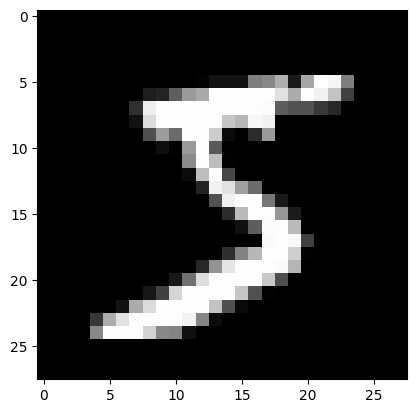

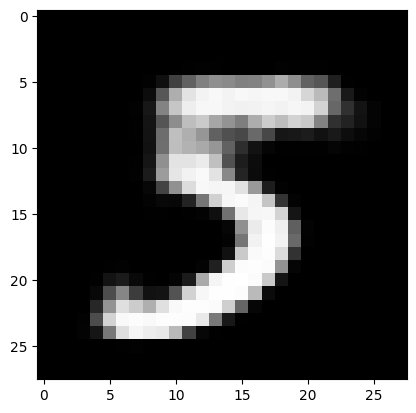

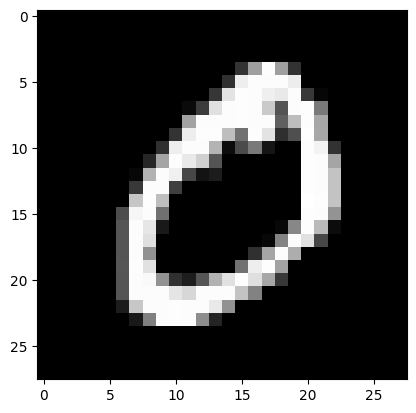

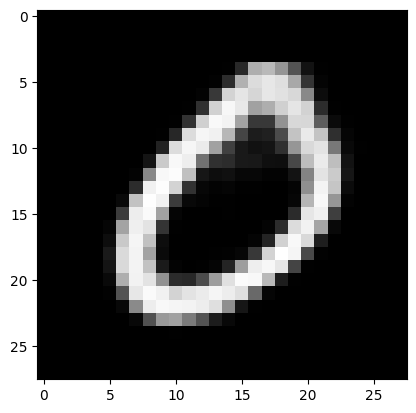

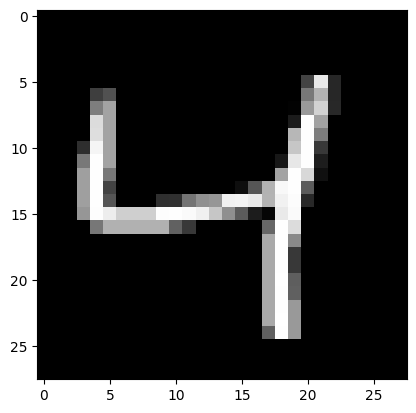

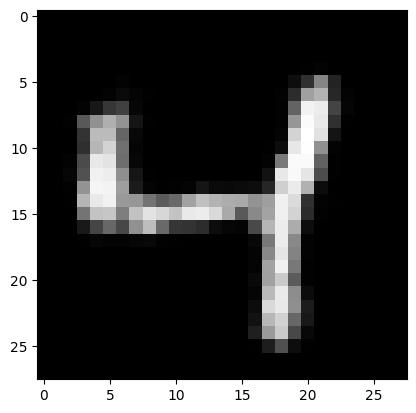

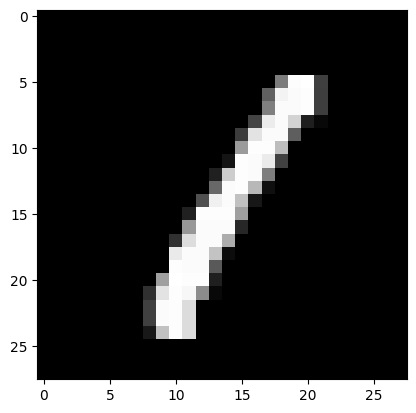

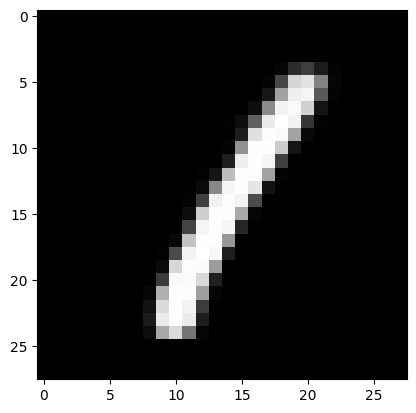

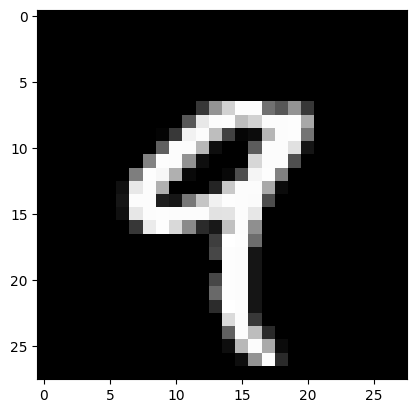

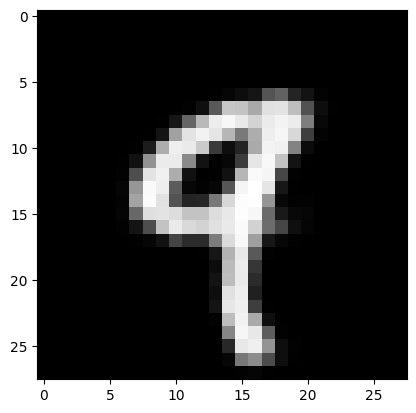

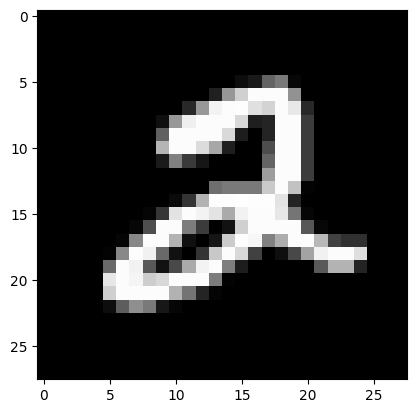

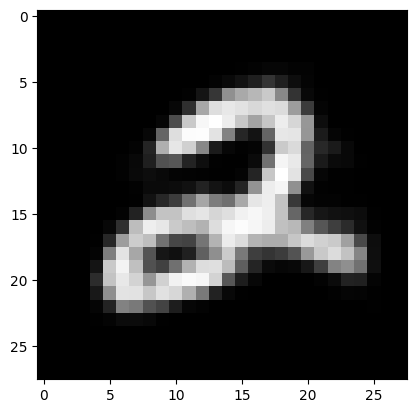

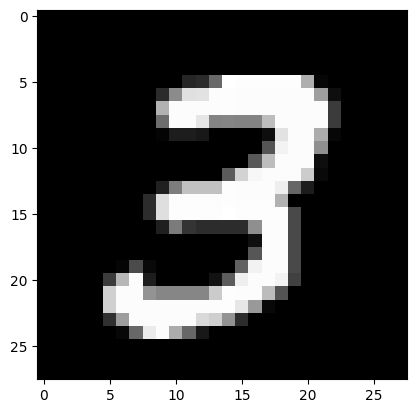

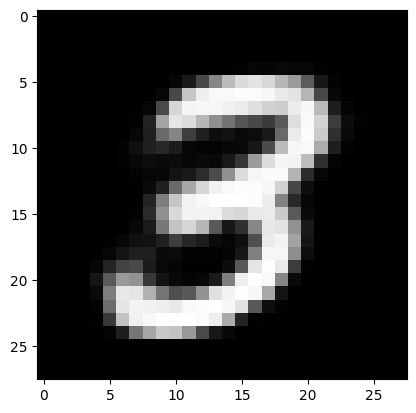

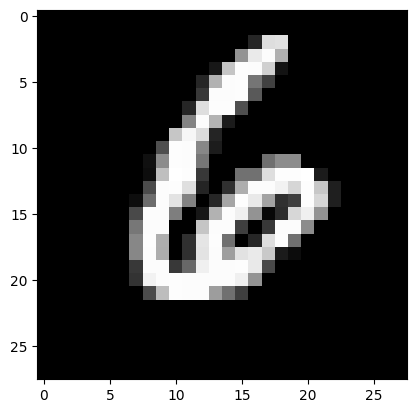

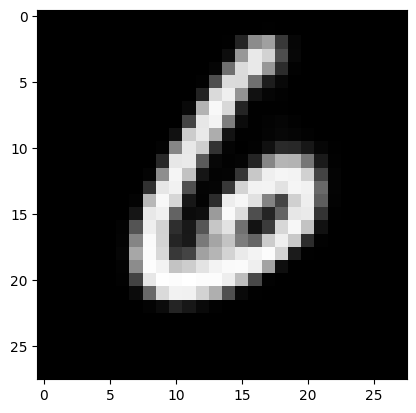

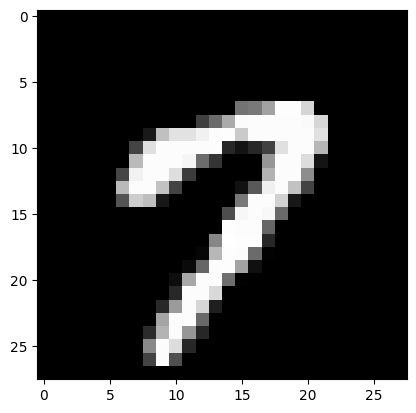

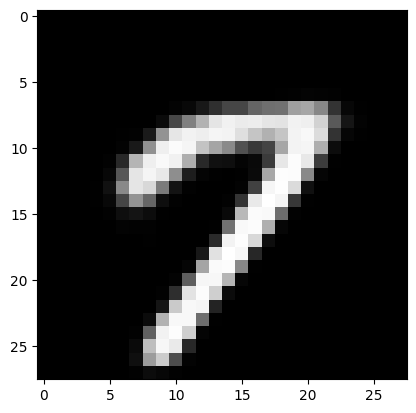

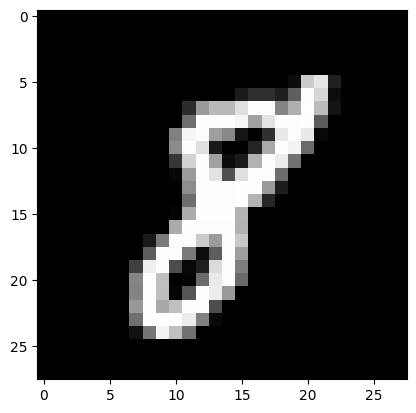

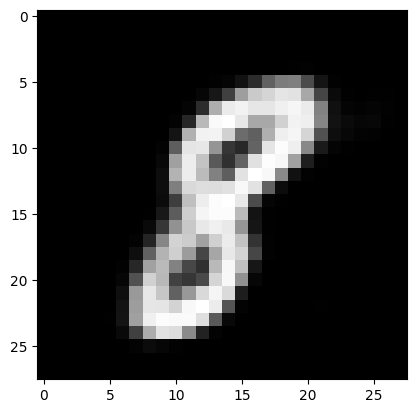

In [6]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		reconstructed = model(image_tensor)[0]
		reconstructed = torch.sigmoid(reconstructed)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Reconstructed from mean

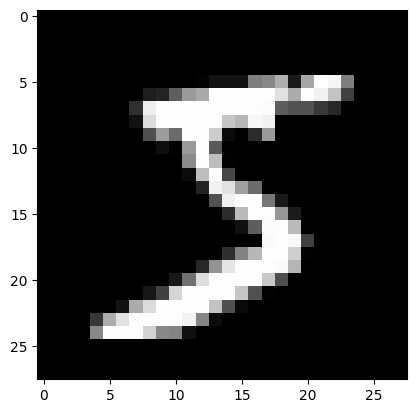

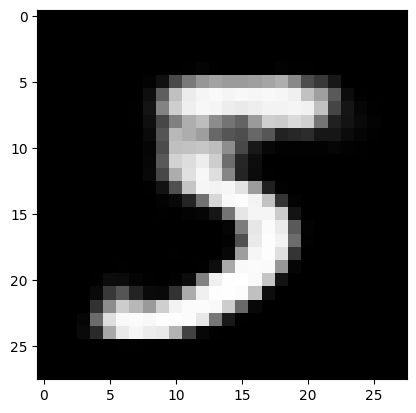

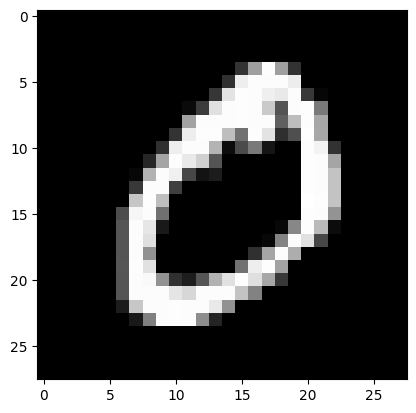

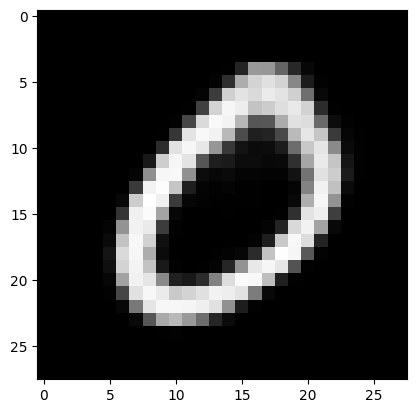

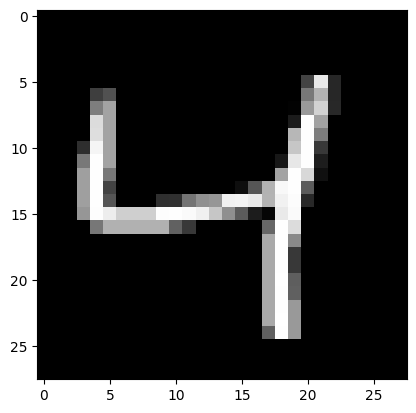

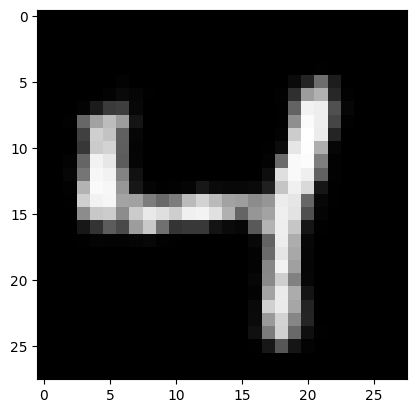

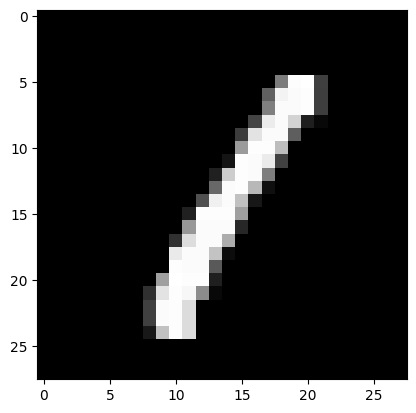

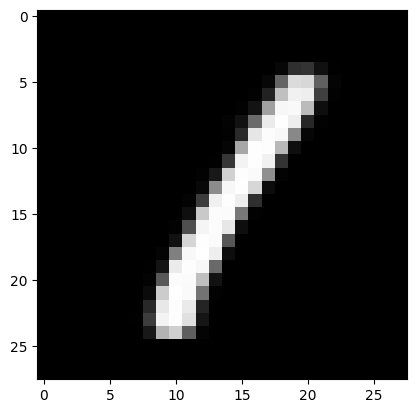

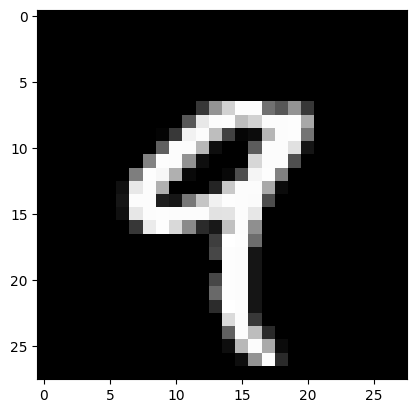

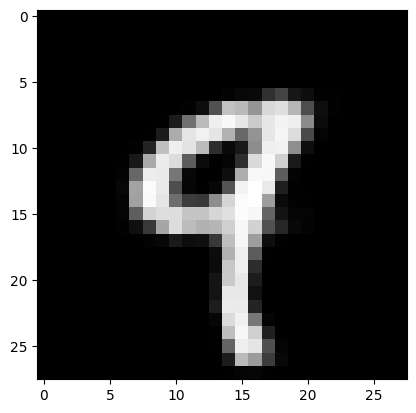

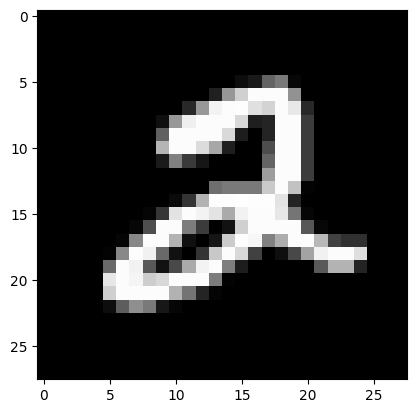

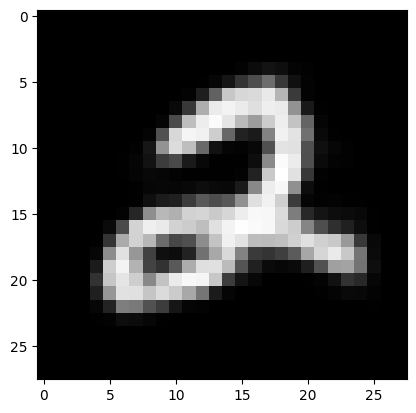

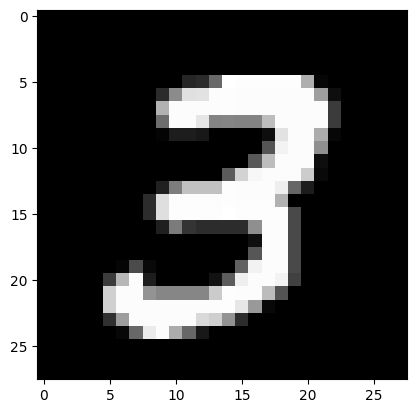

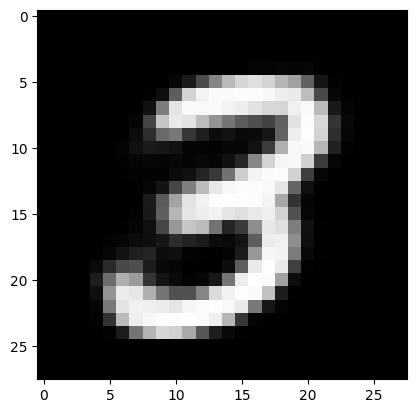

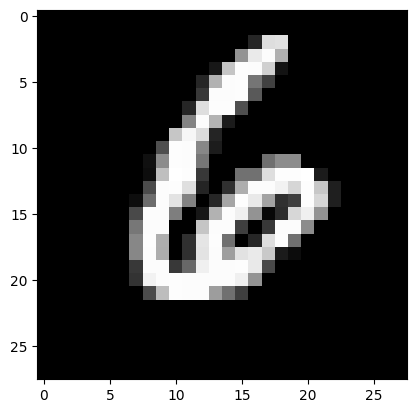

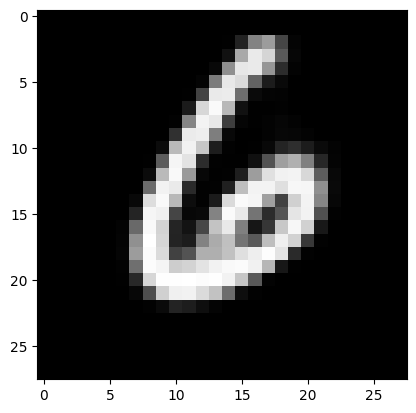

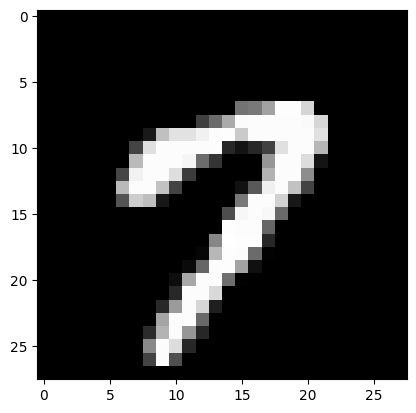

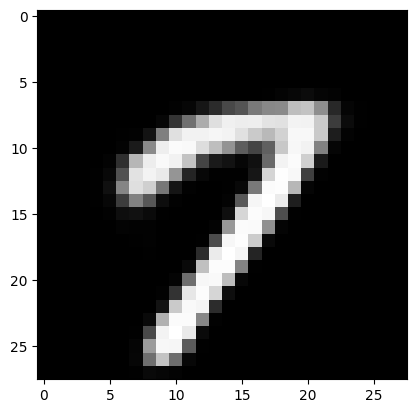

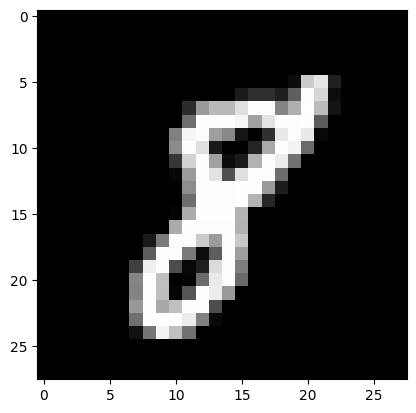

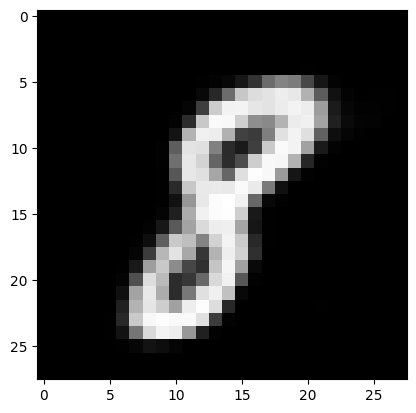

In [7]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		mu = model(image_tensor)[1]
		logits = model.decode(mu)
		reconstructed = torch.sigmoid(logits)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [8]:
model = Conv_VAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)

        z = model.encode(images)[0]

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [9]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [10]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6710
NMI: 0.7251


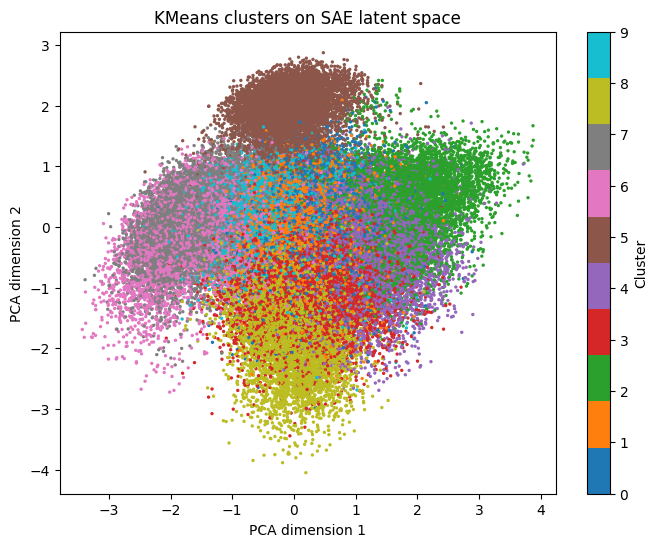

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on ConvVAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

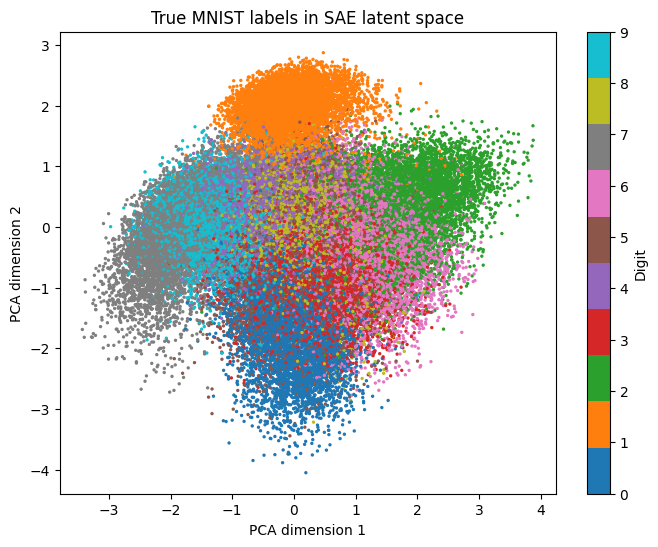

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in ConvVAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


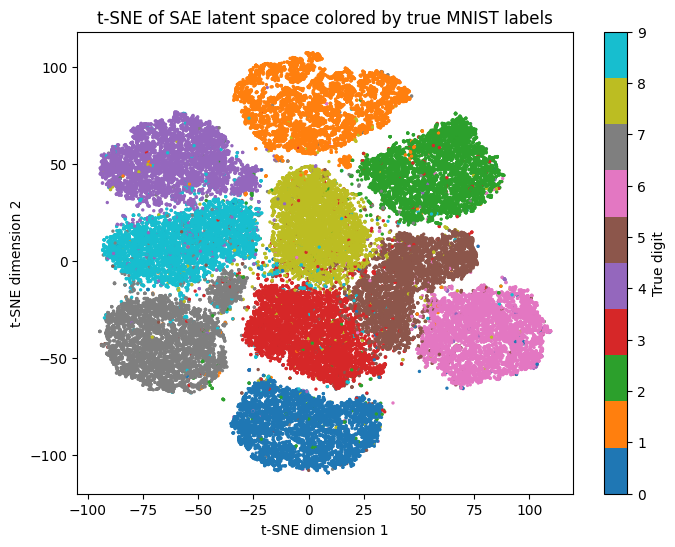

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of ConvVAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

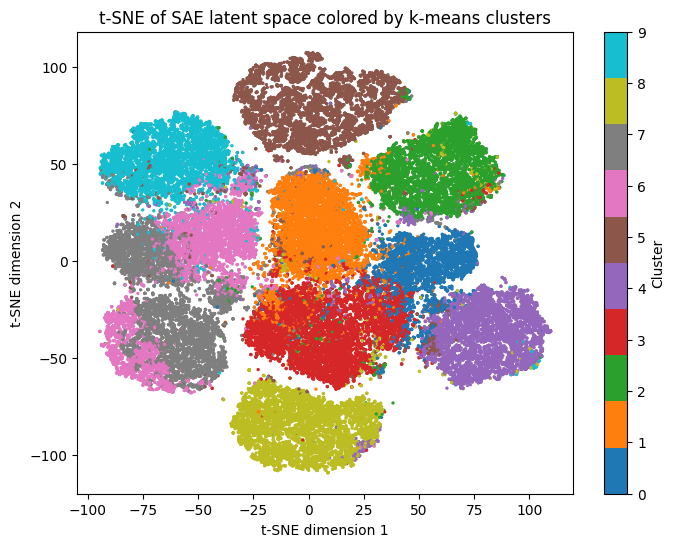

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of ConvVAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [16]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.8066


In [17]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,4,16,6,190,23,3871,361,0,126,13
1,25,18,276,592,5,249,39,12,5939,89
2,7,136,6031,181,28,0,9,96,16,15
3,11,5,85,5860,0,1954,18,1,202,94
4,125,9,192,22,200,98,6158,4,67,25
5,20,7664,64,35,168,33,200,30,186,76
6,9,12,44,107,439,20,0,2475,62,3872
7,10,12,93,84,220,9,1,4650,124,2536
8,6688,1,187,68,11,74,52,9,76,25


In [18]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.00,0.04,0.00,0.84,0.08,0.00,0.03,0.00
1,0.00,0.00,0.04,0.08,0.00,0.03,0.01,0.00,0.82,0.01
2,0.00,0.02,0.93,0.03,0.00,0.00,0.00,0.01,0.00,0.00
3,0.00,0.00,0.01,0.71,0.00,0.24,0.00,0.00,0.02,0.01
4,0.02,0.00,0.03,0.00,0.03,0.01,0.89,0.00,0.01,0.00
5,0.00,0.90,0.01,0.00,0.02,0.00,0.02,0.00,0.02,0.01
6,0.00,0.00,0.01,0.02,0.06,0.00,0.00,0.35,0.01,0.55
7,0.00,0.00,0.01,0.01,0.03,0.00,0.00,0.60,0.02,0.33
8,0.93,0.00,0.03,0.01,0.00,0.01,0.01,0.00,0.01,0.00


## Convolutional VAE Beta Warm up

### Train

In [ ]:
activation_func = "Conv_VAE_warmup"

class Conv_VAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(
                1, 32, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
            ),
            nn.ReLU(),

            nn.Conv2d(
                32, 64, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
            ),
            nn.ReLU(),

            nn.Flatten()
        )

        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 7 * 7),
            nn.Unflatten(1, (64, 7, 7)),

            nn.ConvTranspose2d(
                64, 32,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvae = self.fc_logvar(h)
        return mu, logvae
    
    def decode(self, z):
        return self.decoder(z)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_reconstructed = self.decode(z)
        return (x_reconstructed, mu, logvar)

In [36]:
model = Conv_VAE()
model.to(device)

pretrain_epochs = 400

#loss_function = nn.BCELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-3,
    weight_decay = 1e-4
)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    beta = min(1.0, epoch / 50)

    batch_losses = []
    batch_recons = []
    batch_kls = []
    
    for images, _ in dataloader:

        images = images.to(device)
        reconstructed = model(images)

        # Reconstruction loss
        recon_loss = F.binary_cross_entropy_with_logits(
            reconstructed[0],
            images,
            reduction = "sum"
        ) / images.size(0)

        # KL Divergence
        kl_loss = -0.5 * torch.sum(1 + reconstructed[2] - reconstructed[1]**2 - reconstructed[2].exp(), dim = 1).mean()

        # Total Loss (ELBO)
        loss = recon_loss + (beta * kl_loss)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
        batch_recons.append(recon_loss.item())
        batch_kls.append(kl_loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(
        f"Epoch {epoch+1}/{pretrain_epochs} | "
        f"loss = {sum(batch_losses)/len(batch_losses):.4f} | "
        f"recon = {sum(batch_recons)/len(batch_recons):.4f} | "
        f"kl = {sum(batch_kls)/len(batch_kls):.4f}"
    )

    if epoch == pretrain_epochs - 1:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Epoch 1/400 | loss=170.9342 | recon=170.9342 | kl=808.2508
Epoch 2/400 | loss=118.4413 | recon=114.6610 | kl=189.0151
Epoch 3/400 | loss=108.6731 | recon=105.1815 | kl=87.2902
Epoch 4/400 | loss=103.1234 | recon=99.5050 | kl=60.3064
Epoch 5/400 | loss=99.8979 | recon=96.0654 | kl=47.9065
Epoch 6/400 | loss=97.9592 | recon=93.8308 | kl=41.2846
Epoch 7/400 | loss=96.6531 | recon=92.1811 | kl=37.2672
Epoch 8/400 | loss=95.8468 | recon=90.9819 | kl=34.7497
Epoch 9/400 | loss=95.2947 | recon=90.0249 | kl=32.9361
Epoch 10/400 | loss=94.9397 | recon=89.2454 | kl=31.6349
Epoch 11/400 | loss=94.7222 | recon=88.6090 | kl=30.5659
Epoch 12/400 | loss=94.6207 | recon=88.0803 | kl=29.7291
Epoch 13/400 | loss=94.6275 | recon=87.6569 | kl=29.0441
Epoch 14/400 | loss=94.6401 | recon=87.2522 | kl=28.4149
Epoch 15/400 | loss=94.7732 | recon=86.9680 | kl=27.8755
Epoch 16/400 | loss=94.8622 | recon=86.6418 | kl=27.4012
Epoch 17/400 | loss=95.0598 | recon=86.4220 | kl=26.9931
Epoch 18/400 | loss=95.2560 | r

### Visualize

In [37]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = Conv_VAE()
model.to(device)

Conv_VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=3136, out_features=10, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=10, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=10, out_features=3136, bias=True)
    (1): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (2): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  )
)

#### reconstructed from input

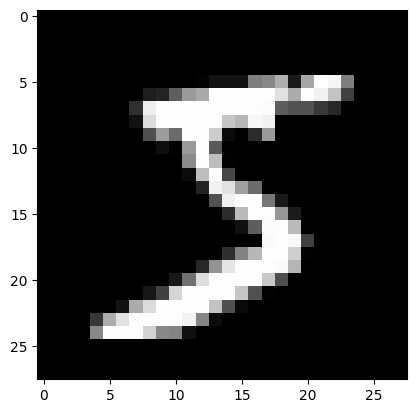

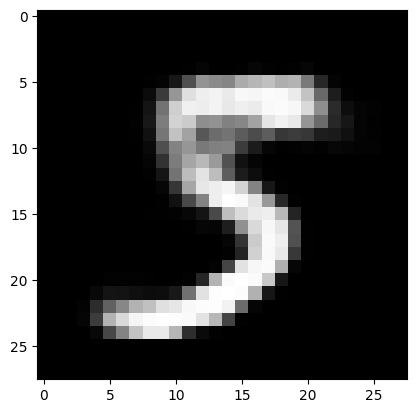

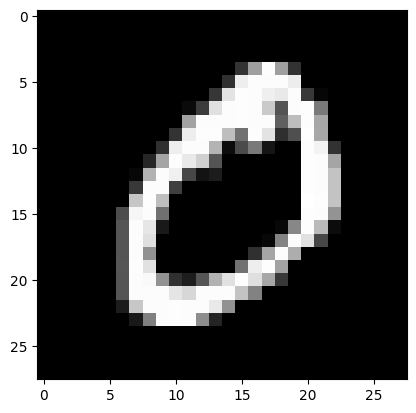

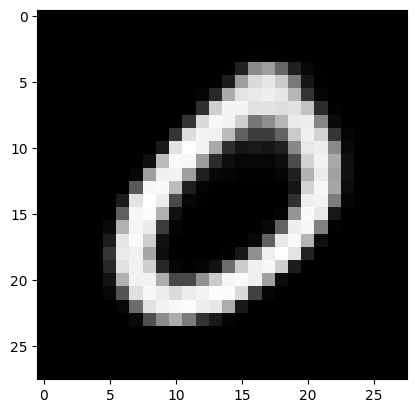

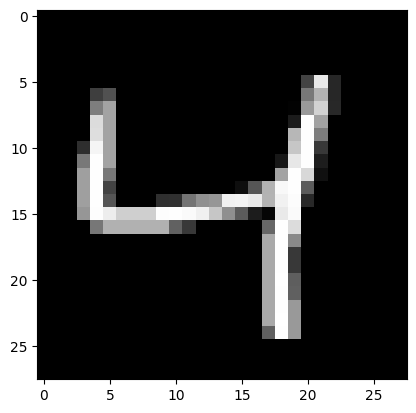

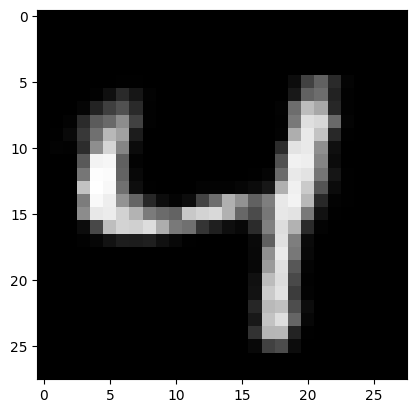

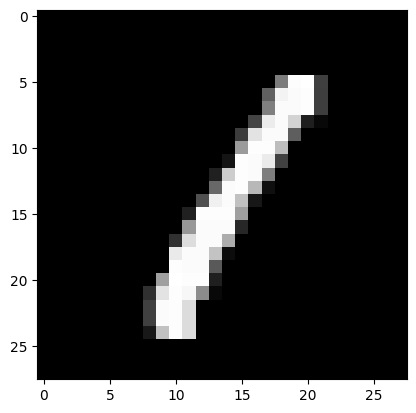

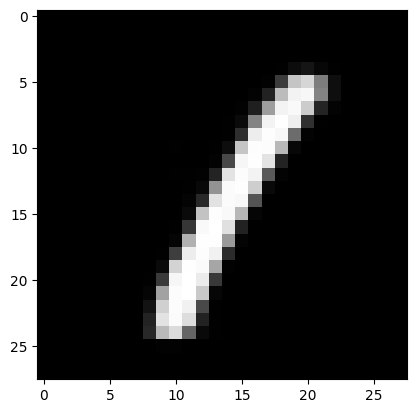

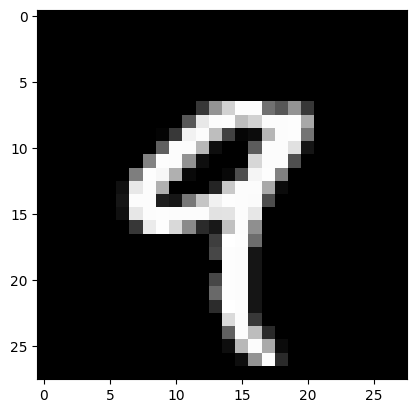

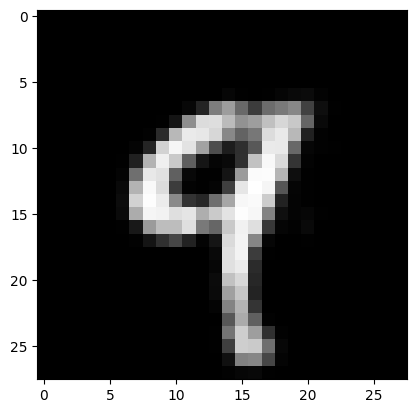

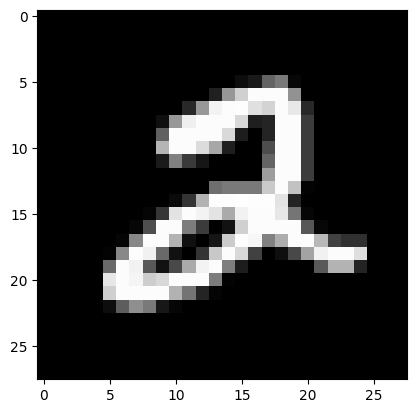

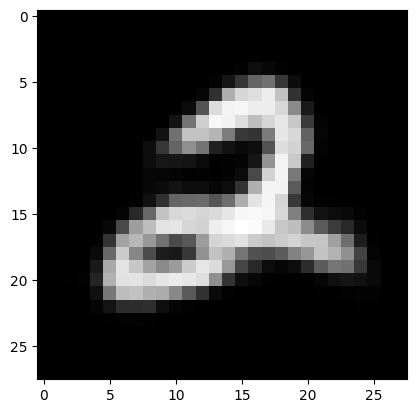

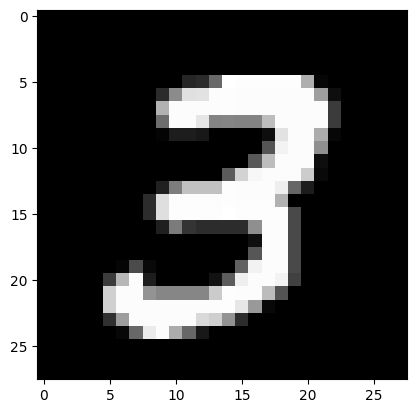

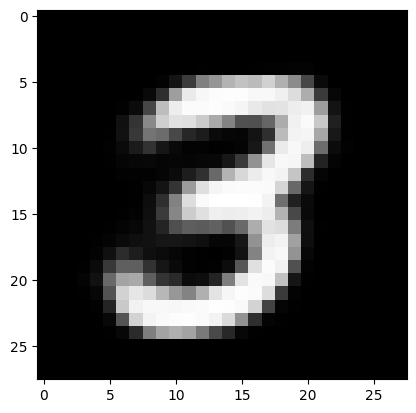

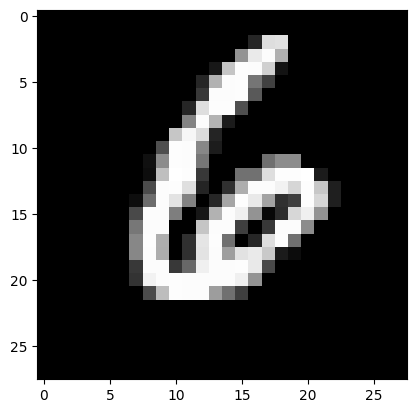

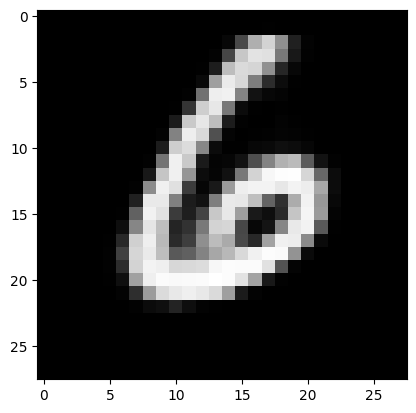

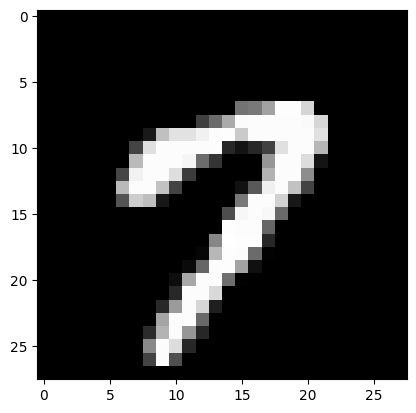

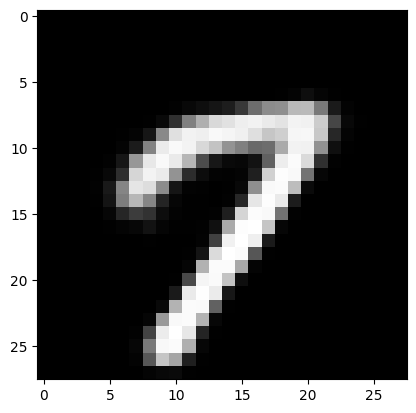

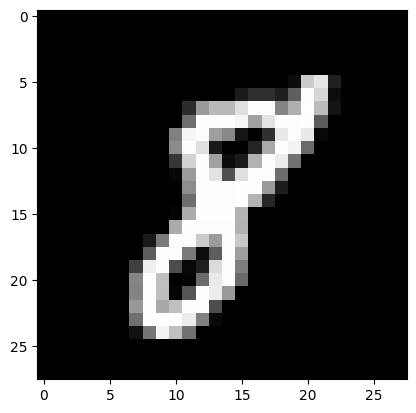

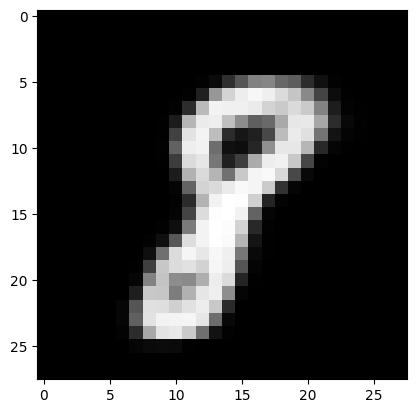

In [38]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		reconstructed = model(image_tensor)[0]
		reconstructed = torch.sigmoid(reconstructed)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Reconstructed from mean

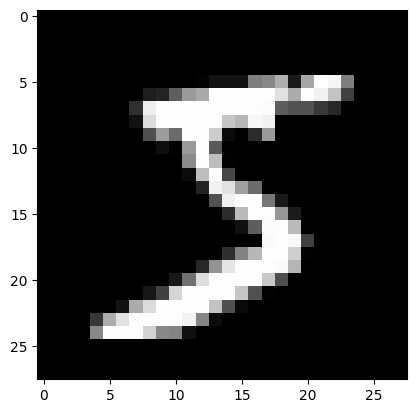

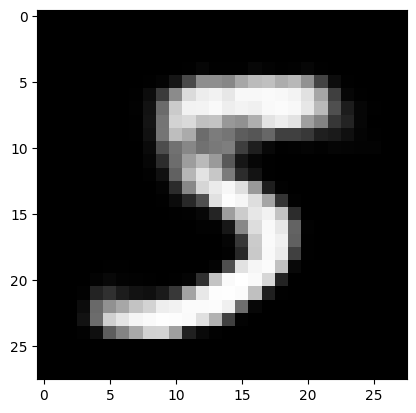

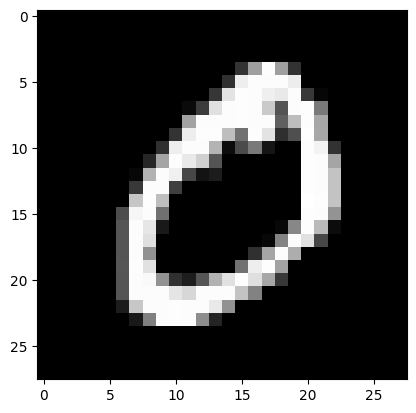

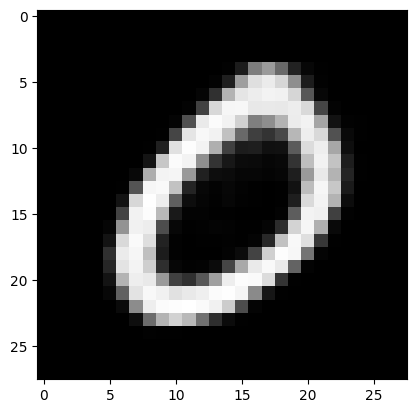

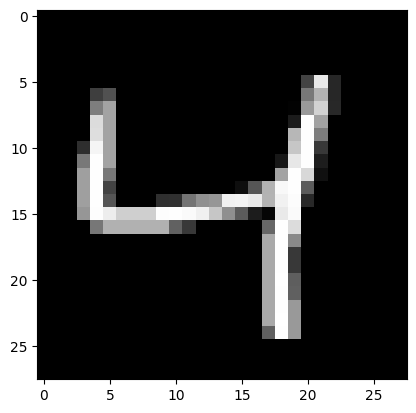

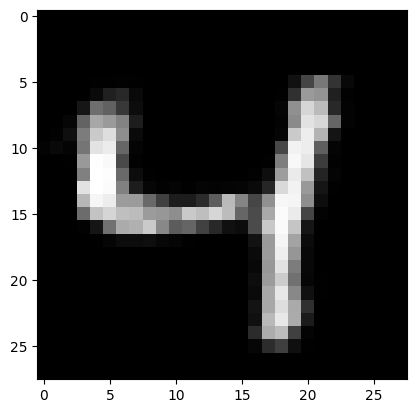

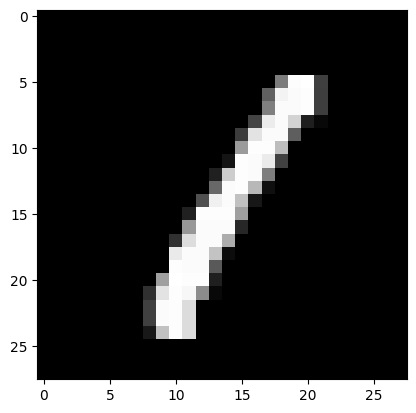

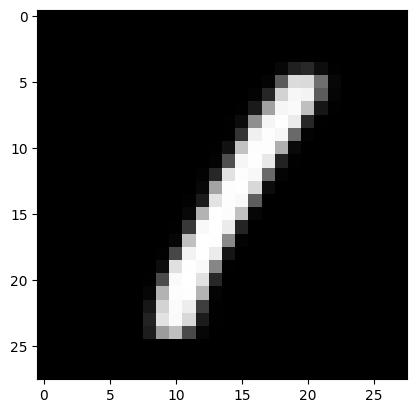

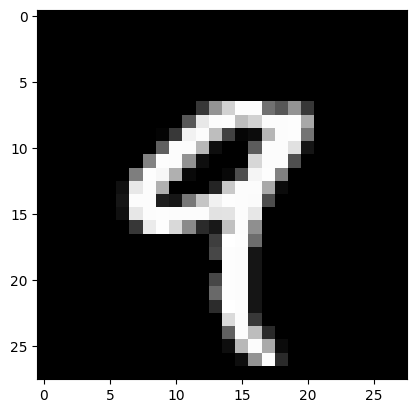

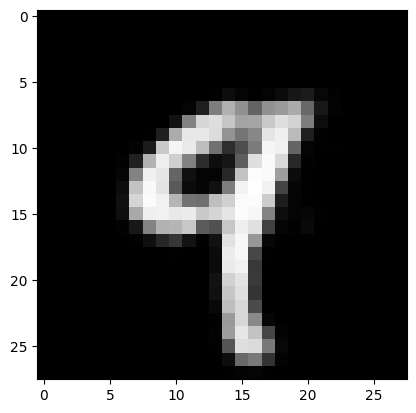

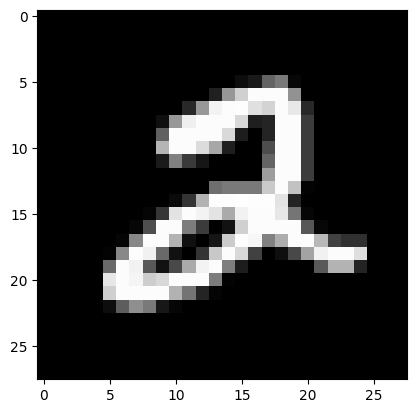

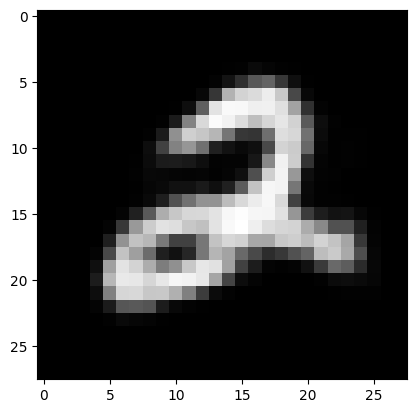

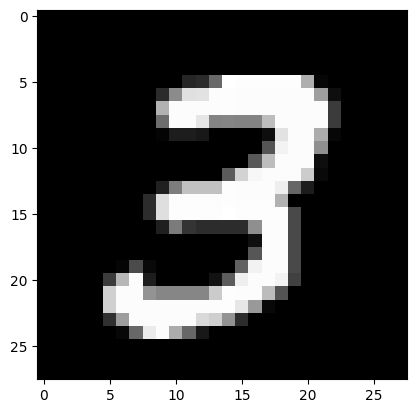

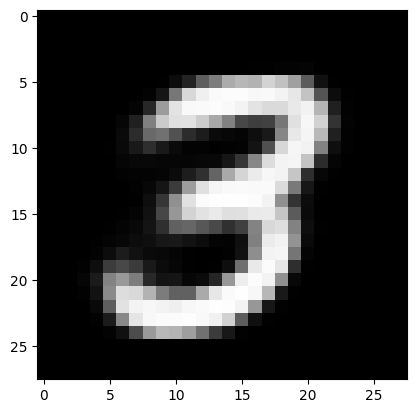

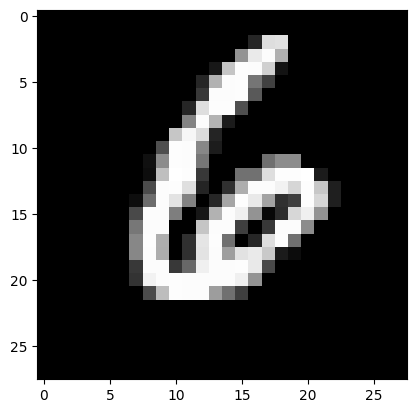

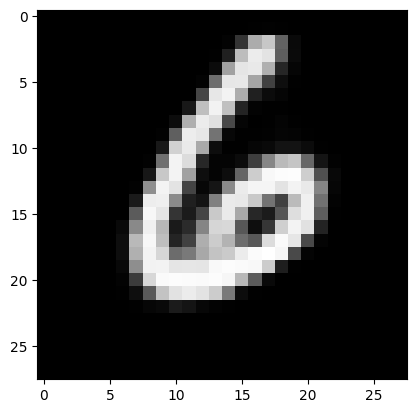

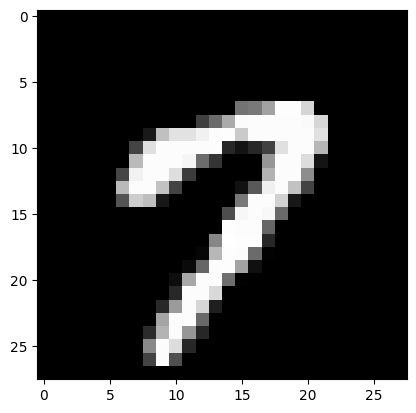

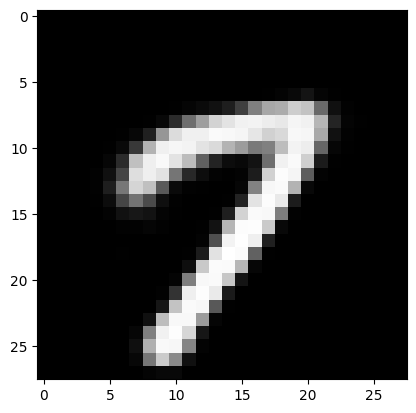

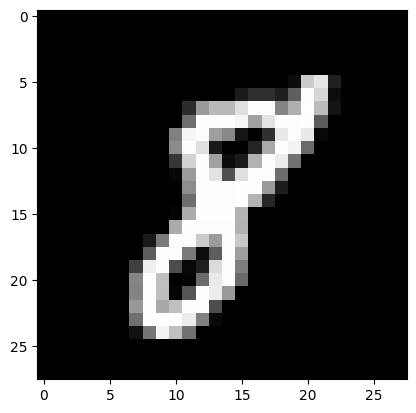

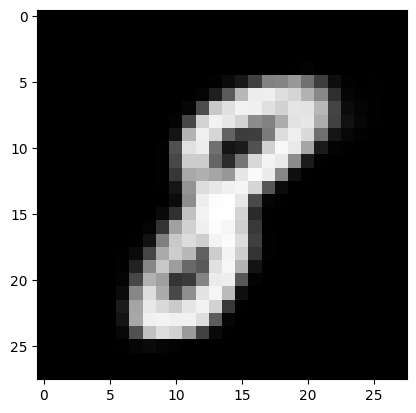

In [39]:
model.load_state_dict(torch.load("./models/" + activation_func + "/model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		mu = model(image_tensor)[1]
		logits = model.decode(mu)
		reconstructed = torch.sigmoid(logits)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [40]:
model = Conv_VAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)

        z = model.encode(images)[0]

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [41]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [42]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6759
NMI: 0.7241


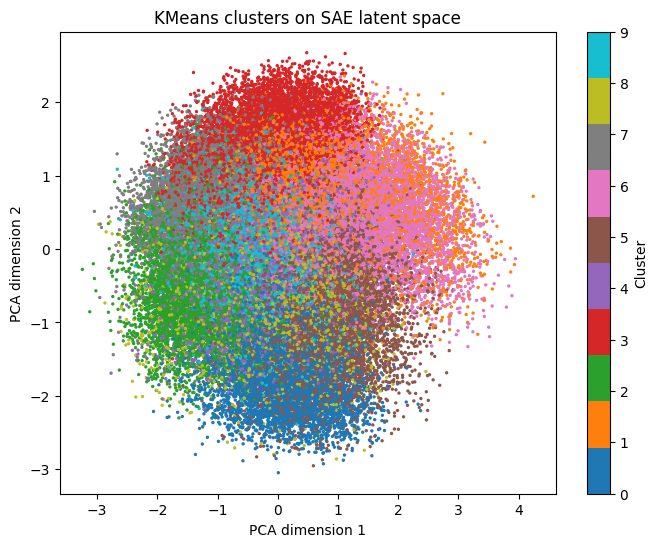

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on ConvVAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

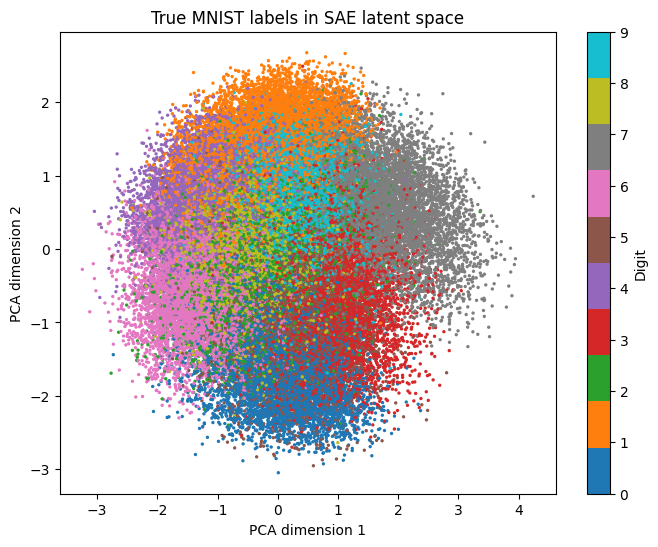

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in ConvVAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [45]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


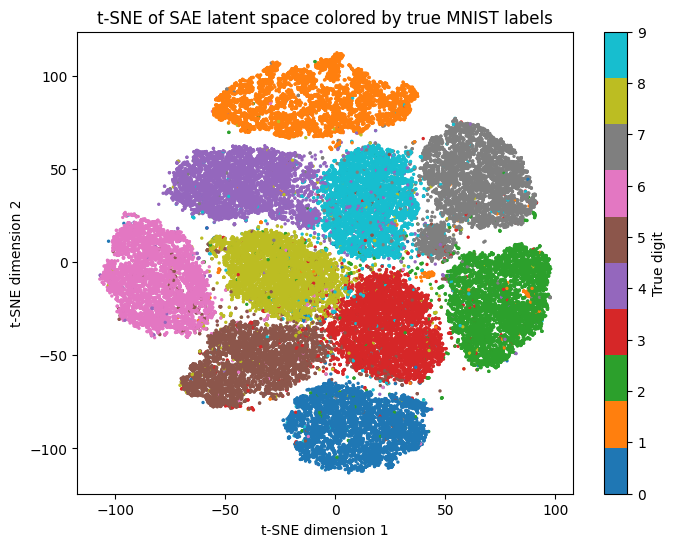

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of ConvVAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

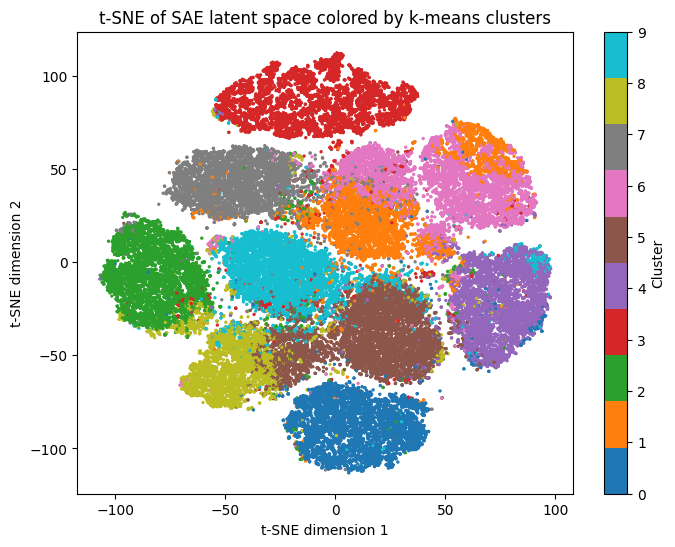

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of ConvVAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [48]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.8128


In [49]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,6714,0,197,60,10,57,27,14,45,32
1,22,17,95,174,509,27,0,1997,133,3801
2,45,5,86,1,177,90,6140,0,52,4
3,17,7658,47,30,108,27,79,57,143,109
4,8,123,5914,157,26,2,19,105,13,10
5,22,3,109,5914,0,1857,8,1,215,114
6,16,6,152,64,104,29,1,5081,101,2459
7,9,7,16,1,5829,5,76,19,32,330
8,14,34,36,242,44,3922,483,5,165,27


In [50]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.94,0.00,0.03,0.01,0.00,0.01,0.00,0.00,0.01,0.00
1,0.00,0.00,0.01,0.03,0.08,0.00,0.00,0.29,0.02,0.56
2,0.01,0.00,0.01,0.00,0.03,0.01,0.93,0.00,0.01,0.00
3,0.00,0.93,0.01,0.00,0.01,0.00,0.01,0.01,0.02,0.01
4,0.00,0.02,0.93,0.02,0.00,0.00,0.00,0.02,0.00,0.00
5,0.00,0.00,0.01,0.72,0.00,0.23,0.00,0.00,0.03,0.01
6,0.00,0.00,0.02,0.01,0.01,0.00,0.00,0.63,0.01,0.31
7,0.00,0.00,0.00,0.00,0.92,0.00,0.01,0.00,0.01,0.05
8,0.00,0.01,0.01,0.05,0.01,0.79,0.10,0.00,0.03,0.01
